# Drzewa decyzyjne – wprowadzenie

**Plan notatnika:**
1. Czym jest drzewo decyzyjne
2. Jak drzewo się uczy
3. Kryteria podziału: Gini i entropia
4. Drzewo regresyjne
5. Najważniejsze hiperparametry
6. Zalety i wady
7. Podsumowanie

## 1. Czym jest drzewo decyzyjne

Drzewo decyzyjne to model, który podejmuje decyzję, zadając **serię prostych pytań** o cechy obiektu (np. „czy wiek < 30?”). Odpowiedzi prowadzą od góry do dołu drzewa, aż do **liścia**, który zawiera wynik: klasę (klasyfikacja) albo liczbę (regresja).

![Struktura drzewa decyzyjnego](../obrazki/4.1_struktura_drzewa.png)

| Pojęcie | Znaczenie |
|---|---|
| **węzeł główny (korzeń)** | pierwszy węzeł; zawiera wszystkie dane i zadaje pierwsze pytanie |
| **węzeł wewnętrzny (decyzyjny)** | węzeł z pytaniem, który dzieli dane na dwa podzbiory |
| **liść** | węzeł końcowy, bez dzieci; zawiera wynik |
| **rodzic i dzieci** | węzeł, który został podzielony, jest rodzicem; powstałe z niego węzły to dzieci |
| **głębokość drzewa** | liczba poziomów podziałów od korzenia do najgłębszego liścia |
| **przycinanie (pruning)** | usuwanie zbędnych węzłów lub ograniczanie wzrostu drzewa, żeby model się nie przeuczył |

W scikit-learn drzewa są **binarne**: każdy podział to dwa dzieci (warunek spełniony lub nie).

### Przykład z życia

![Drzewo: czy osoba jest wysportowana](../obrazki/4.1_przyklad_wysportowany.png)

To drzewo to po prostu zagnieżdżone instrukcje `if`/`else`. Różnica w stosunku do zwykłego programowania jest taka, że **pytania i progi (np. 30 lat) dobiera algorytm na podstawie danych**, a nie programista.

## 2. Jak drzewo się uczy

Algorytm buduje drzewo od góry (korzenia) w dół, krok po kroku:

1. **Wybór podziału** – w danym węźle sprawdza **każdą cechę i każdy możliwy próg** i wybiera ten podział, po którym dzieci są jak najbardziej „czyste” (jedna klasa dominuje).
2. **Podział danych** – obserwacje trafiają do lewego lub prawego dziecka zależnie od spełnienia warunku.
3. **Rekurencja** – to samo powtarzamy osobno dla każdego dziecka.
4. **Zatrzymanie** – kończymy, gdy węzeł jest już czysty (jedna klasa) albo zadziała ograniczenie, np. maksymalna głębokość lub minimalna liczba obserwacji w liściu.

Algorytm jest **zachłanny**: w każdym węźle wybiera podział najlepszy *w tym momencie*, bez planowania całego drzewa. Dlatego nie gwarantuje najlepszego możliwego drzewa, ale działa szybko i dobrze w praktyce.

Co to znaczy „czysty” węzeł i jak to zmierzyć? Do tego służą kryteria podziału.

## 3. Kryteria podziału: Gini i entropia

Miarą „nieczystości” węzła są dwa popularne wzory. Niech $p_k$ oznacza **udział klasy $k$** w węźle.

- **Nieczystość Giniego** (domyślna w scikit-learn, `criterion='gini'`):

$$
Gini = 1 - \sum_k p_k^2
$$

- **Entropia** (`criterion='entropy'`):

$$
Entropia = -\sum_k p_k \log_2 p_k
$$

Obie miary są równe 0, gdy w węźle jest tylko jedna klasa (węzeł czysty), a największe, gdy klasy są wymieszane po równo. W praktyce dają bardzo podobne drzewa.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

def gini(y):
    p = np.bincount(y) / len(y)
    return 1 - np.sum(p ** 2)

def entropia(y):
    p = np.bincount(y) / len(y)
    p = p[p > 0]                      # 0 * log(0) przyjmujemy jako 0
    return np.sum(p * np.log2(1 / p))

# węzły o różnym wymieszaniu klas: [liczba klasy 0, liczba klasy 1]
for ile_0, ile_1 in [(10, 0), (9, 1), (7, 3), (5, 5)]:
    y_wezla = np.array([0] * ile_0 + [1] * ile_1)
    print(f'klasy [{ile_0:2d}, {ile_1:2d}]:  Gini = {gini(y_wezla):.3f}   entropia = {entropia(y_wezla):.3f}')

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


klasy [10,  0]:  Gini = 0.000   entropia = 0.000
klasy [ 9,  1]:  Gini = 0.180   entropia = 0.469
klasy [ 7,  3]:  Gini = 0.420   entropia = 0.881
klasy [ 5,  5]:  Gini = 0.500   entropia = 1.000


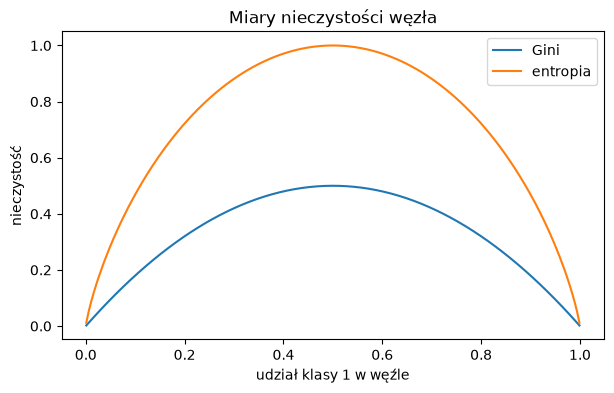

In [2]:
# jak miary zależą od udziału klasy 1 (dla dwóch klas)
p = np.linspace(0.001, 0.999, 200)
gini_p = 1 - p ** 2 - (1 - p) ** 2
entropia_p = -p * np.log2(p) - (1 - p) * np.log2(1 - p)

plt.figure(figsize=(7, 4))
plt.plot(p, gini_p, label='Gini')
plt.plot(p, entropia_p, label='entropia')
plt.xlabel('udział klasy 1 w węźle')
plt.ylabel('nieczystość')
plt.title('Miary nieczystości węzła')
plt.legend()
plt.show()

Obie krzywe mają maksimum przy $p = 0{,}5$ (klasy po równo) i spadają do 0 przy czystym węźle. Entropia ma tylko większą skalę (maksimum 1, a Gini 0,5).

### Jak oceniany jest podział

Dla kandydata na podział liczymy **ważoną nieczystość dzieci** (waga = udział obserwacji w dziecku):

$$
Gini_{podział} = \frac{n_{lewe}}{n}\, Gini_{lewe} + \frac{n_{prawe}}{n}\, Gini_{prawe}
$$

Wygrywa podział z **najniższą** wartością, czyli z największym spadkiem nieczystości względem rodzica (tzw. *zysk informacji*). Jeśli żaden podział nie zmniejsza nieczystości, węzeł zostaje liściem.

Zróbmy to ręcznie na małym zbiorze: 12 osób, cel to `wysportowany` (1 = tak).

In [5]:
osoby = pd.DataFrame({
    'wiek':         [22, 25, 28, 31, 35, 38, 42, 47, 52, 58, 63, 70],
    'trening_h':    [5,  4,  0,  3,  1,  4,  0,  2,  3,  0,  1,  0],   # godziny treningu w tygodniu
    'fast_food':    [1,  2,  4,  1,  5,  2,  3,  1,  2,  4,  3,  5],   # posiłki fast food w tygodniu
    'wysportowany': [1,  1,  0,  1,  1,  1,  0,  0,  1,  0,  0,  0],
})
X = osoby.drop(columns='wysportowany')
y = osoby['wysportowany'].to_numpy()

print('Nieczystość korzenia (wszystkie 12 osób): Gini =', round(gini(y), 3))

Nieczystość korzenia (wszystkie 12 osób): Gini = 0.5


In [11]:
osoby

,wiek,trening_h,fast_food,wysportowany
0,22,5,1,1
1,25,4,2,1
2,28,0,4,0
3,31,3,1,1
4,35,1,5,1
5,38,4,2,1
6,42,0,3,0
7,47,2,1,0
8,52,3,2,1
9,58,0,4,0


In [10]:
def najlepszy_podzial(x, y):
    """Sprawdza wszystkie progi (środki między sąsiednimi wartościami) i zwraca najlepszy."""
    wartosci = np.unique(x)
    progi = (wartosci[:-1] + wartosci[1:]) / 2
    najlepszy = None
    for prog in progi:
        lewe, prawe = y[x <= prog], y[x > prog]
        wazona = len(lewe) / len(y) * gini(lewe) + len(prawe) / len(y) * gini(prawe)
        if najlepszy is None or wazona < najlepszy[1]:
            najlepszy = (prog, wazona)
    return najlepszy

for cecha in X.columns:
    prog, wazona = najlepszy_podzial(X[cecha].to_numpy(), y)
    print(f'{cecha:10s}: najlepszy próg {prog:5.1f}, ważony Gini po podziale = {wazona:.3f}, '
          f'zysk = {gini(y) - wazona:.3f}')

wiek      : najlepszy próg  40.0, ważony Gini po podziale = 0.278, zysk = 0.222
trening_h : najlepszy próg   2.5, ważony Gini po podziale = 0.143, zysk = 0.357
fast_food : najlepszy próg   2.5, ważony Gini po podziale = 0.278, zysk = 0.222


Najlepszą cechą jest ta, po której ważony Gini jest najniższy (zysk największy). Sprawdźmy, czy `DecisionTreeClassifier` wybierze dokładnie to samo w korzeniu:

Cecha w korzeniu: trening_h
Próg: 2.5
Gini węzłów [korzeń, lewe, prawe]: [0.5   0.245 0.    0.5   0.   ]


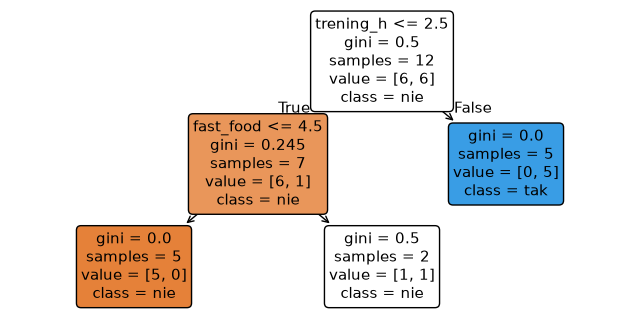

In [18]:
drzewo = DecisionTreeClassifier(max_depth=2, random_state=42)
drzewo.fit(X, y)

print('Cecha w korzeniu:', X.columns[drzewo.tree_.feature[0]])
print('Próg:', drzewo.tree_.threshold[0])
print('Gini węzłów [korzeń, lewe, prawe]:', drzewo.tree_.impurity.round(3))

plt.figure(figsize=(8, 4))
plot_tree(drzewo, feature_names=list(X.columns), class_names=['nie', 'tak'], filled=True, rounded=True)
plt.show()

Wynik zgadza się z ręcznym rachunkiem. Każdy węzeł na rysunku pokazuje: warunek podziału, `gini`, liczbę obserwacji (`samples`), liczby obserwacji w klasach (`value`) oraz klasę większościową (`class`). Kolor to klasa większościowa, a jego intensywność – czystość węzła.

**Co przewiduje liść?** Klasę większościową. `predict_proba` zwraca udziały klas w liściu (np. liść z 6 osobami „nie” i 1 „tak” daje prawdopodobieństwo $\tfrac{1}{7}$).

## 4. Drzewo regresyjne

Drzewo może też przewidywać **liczby** (`DecisionTreeRegressor`). Podział wybiera się wtedy tak, aby zmniejszyć **błąd średniokwadratowy** (zamiast Gini), a **liść zwraca średnią** wartości zmiennej celu z obserwacji, które do niego trafiły. Model jest więc funkcją **schodkową**.

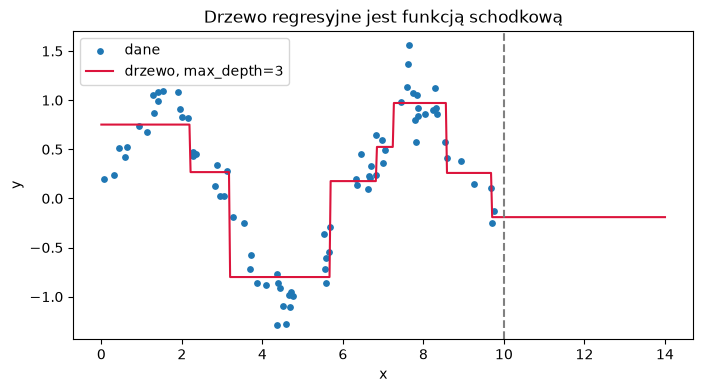

In [20]:
rng = np.random.default_rng(42)
x = np.sort(rng.uniform(0, 10, 80))
y_reg = np.sin(x) + rng.normal(0, 0.2, size=len(x))

reg = DecisionTreeRegressor(max_depth=3, random_state=42)
reg.fit(x.reshape(-1, 1), y_reg)

x_siatka = np.linspace(0, 14, 500).reshape(-1, 1)       # siatka sięga poza zakres danych (do 14)

plt.figure(figsize=(8, 4))
plt.scatter(x, y_reg, s=15, label='dane')
plt.plot(x_siatka, reg.predict(x_siatka), color='crimson', label='drzewo, max_depth=3')
plt.axvline(10, color='gray', linestyle='--')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Drzewo regresyjne jest funkcją schodkową')
plt.legend()
plt.show()

Dwie ważne obserwacje:
- predykcja jest **stała w każdym przedziale** (schodki) – im głębsze drzewo, tym więcej schodków,
- **drzewo nie ekstrapoluje**: poza zakresem danych (na prawo od przerywanej linii) zwraca ostatnią średnią, zamiast kontynuować trend jak regresja liniowa.

## 5. Najważniejsze hiperparametry

Drzewo bez ograniczeń rośnie, aż każdy liść będzie czysty, czyli **zapamiętuje dane treningowe** (przeuczenie). Wzrost kontrolujemy hiperparametrami:

| Hiperparametr | Co robi |
|---|---|
| `max_depth` | maksymalna głębokość drzewa |
| `min_samples_split` | minimalna liczba obserwacji w węźle, żeby w ogóle go dzielić |
| `min_samples_leaf` | minimalna liczba obserwacji w liściu |
| `max_leaf_nodes` | maksymalna liczba liści |
| `ccp_alpha` | siła przycinania drzewa po jego zbudowaniu (większa wartość = mniejsze drzewo) |
| `criterion` | kryterium podziału: `'gini'`, `'entropy'` (a dla regresji `'squared_error'`) |
| `class_weight` | wagi klas, np. `'balanced'` przy niezbalansowanych danych |

Wpływ tych ustawień na przeuczenie pokażemy w kolejnych notatnikach (4.3 – niedouczenie i przeuczenie, 4.5 – dobór hiperparametrów).

## 6. Zalety i wady

**Zalety:**
- **Interpretowalność** – model to czytelne reguły, które można narysować i wyjaśnić osobie nietechnicznej. To największa zaleta drzew.
- **Nie wymagają skalowania cech** – podział „cecha ≤ próg” nie zależy od skali, więc nie potrzeba `StandardScaler`.
- **Modelują zależności nieliniowe i interakcje** między cechami bez dodatkowej pracy (w przeciwieństwie do regresji liniowej).
- **Są odporne na obserwacje odstające** w cechach (liczy się kolejność wartości, nie ich wielkość) i na cechy skorelowane (przewidywania nie psują się, ale ważność cech rozkłada się między nie).
- **Wbudowana selekcja cech** – drzewo używa tylko tych cech, które pomagają w podziałach (`feature_importances_`).
- **Szybkie** w trenowaniu i predykcji.

**Wady:**
- **Przeuczenie** – głębokie drzewo dopasowuje się do szumu w danych treningowych.
- **Niestabilność** – niewielka zmiana danych może dać zupełnie inne drzewo.
- **Podziały prostopadłe do osi** – granice decyzyjne to prostokąty, więc ukośne zależności wymagają wielu podziałów.
- **Brak ekstrapolacji** – poza zakresem danych predykcja jest stała.
- **Cechy tekstowe wymagają zakodowania** (np. `OneHotEncoder`) – scikit-learn nie przyjmuje kolumn tekstowych.
- Pojedyncze drzewo jest zwykle **słabsze od modeli zespołowych** – dlatego w następnym rozdziale poznamy las losowy, który łączy wiele drzew.

**Z praktyki:** drzewo decyzyjne lub las losowy to często dobry pierwszy model w projekcie – szybko pokazuje, ile informacji niosą dane i które cechy są ważne.

## 7. Podsumowanie

1. Drzewo zadaje pytania o cechy i na tej podstawie dochodzi do liścia z wynikiem.
2. Uczy się **zachłannie**: w każdym węźle wybiera cechę i próg, które najbardziej zmniejszają nieczystość (Gini lub entropię); w regresji – błąd średniokwadratowy.
3. Bez ograniczeń drzewo się przeucza, dlatego kontrolujemy je hiperparametrami (`max_depth`, `min_samples_leaf`, ...).
4. Największa zaleta to interpretowalność, największa wada – przeuczenie i niestabilność.

W kolejnych notatnikach zbudujemy drzewa na trzech zbiorach: **Iris** (wizualizacja granic decyzyjnych), **Heart** (dane medyczne) i **Churn** (odejścia klientów, dane niezbalansowane).